<a href="https://colab.research.google.com/github/Sunny-Mansoor/BlockQuest/blob/main/STI100_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ============================================================
# STI100³ HANDS-ON WORKSHOP TUTORIAL SHEET
# ============================================================
#
# Title:
# Introduction to Python: Data Innovator
#
# Program Theme:
# "Using Data to Make Smart Decisions"

# ------------------------------------------------------------
# LEARNING OUTCOMES
# ------------------------------------------------------------
#
# By the end of this activity, students will be able to:
#
# ✅ Create a simple dataset
# ✅ Understand data preprocessing
# ✅ Explore and visualize data
# ✅ Build a simple classification model
# ✅ Evaluate model performance
# ✅ Understand the Data Science workflow
#
# Data Collection
#        ↓
# Data Preprocessing
#        ↓
# Data Exploration
#        ↓
# Data Modeling
#        ↓
# Evaluation
#
# ============================================================
# SCENARIO
# ============================================================
#
# A school wants to predict whether a student is likely
# to PASS or FAIL based on:
#
# 1. Number of hours studied
# 2. Number of hours slept
#
# Students will use Python to build a simple Machine
# Learning model.
#
# ============================================================
# STEP 1: DATA COLLECTION
# ============================================================
#
# Data Collection refers to gathering information that
# will be used for analysis and prediction.
#
# In this example:
#
# Hours_Studied = Number of hours spent studying
# Hours_Slept   = Number of hours spent sleeping
# Result        = Pass or Fail
#
# ============================================================

In [1]:
import pandas as pd

data = {
    "Hours_Studied": [2, 3, 4, 5, 6, 7, 1, 8, 4, 3],
    "Hours_Slept": [5, 6, 6, 7, 5, 6, 4, 7, 5, 4],
    "Result": [
        "Fail", "Fail", "Pass", "Pass",
        "Pass", "Pass", "Fail",
        "Pass", "Fail", "Fail"
    ]
}

df = pd.DataFrame(data)

print("========== DATASET ==========")
print(df)

========== DATASET ==========
   Hours_Studied  Hours_Slept Result
0              2            5   Fail
1              3            6   Fail
2              4            6   Pass
3              5            7   Pass
4              6            5   Pass
5              7            6   Pass
6              1            4   Fail
7              8            7   Pass
8              4            5   Fail
9              3            4   Fail


# ------------------------------------------------------------
# QUESTIONS
# ------------------------------------------------------------
#
# 1. How many students are in the dataset?
# 2. What information is stored for each student?
# 3. Which column is the target variable?

# ============================================================
# STEP 2: DATA PREPROCESSING
# ============================================================
#
# Data Preprocessing means preparing data before analysis.
#
# Examples:
# - Handle missing values
# - Remove incorrect data
# - Convert text into numbers
#
# Computers understand numbers better than text.
#
# Therefore:
# Fail = 0
# Pass = 1
#
# ============================================================

In [2]:
print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())


========== MISSING VALUES ==========
Hours_Studied    0
Hours_Slept      0
Result           0
dtype: int64


In [3]:
# Convert Pass/Fail into numbers
df["Label"] = df["Result"].map({
    "Fail": 0,
    "Pass": 1
})

print("\n========== AFTER PREPROCESSING ==========")
print(df)


========== AFTER PREPROCESSING ==========
   Hours_Studied  Hours_Slept Result  Label
0              2            5   Fail      0
1              3            6   Fail      0
2              4            6   Pass      1
3              5            7   Pass      1
4              6            5   Pass      1
5              7            6   Pass      1
6              1            4   Fail      0
7              8            7   Pass      1
8              4            5   Fail      0
9              3            4   Fail      0


# ============================================================
# STEP 3: DATA EXPLORATION
# ============================================================
#
# Data Exploration helps us understand the data.
#
# Questions we may ask:
# - What is the average study time?
# - Which student studied the most?
# - How many students passed?
#
# Data scientists usually explore data before building
# machine learning models.
#
# ============================================================


In [4]:
print("\n========== DATA SUMMARY ==========")
print(df.describe())


========== DATA SUMMARY ==========
       Hours_Studied  Hours_Slept      Label
count      10.000000    10.000000  10.000000
mean        4.300000     5.500000   0.500000
std         2.213594     1.080123   0.527046
min         1.000000     4.000000   0.000000
25%         3.000000     5.000000   0.000000
50%         4.000000     5.500000   0.500000
75%         5.750000     6.000000   1.000000
max         8.000000     7.000000   1.000000


In [5]:
print("\n========== PASS / FAIL COUNT ==========")
print(df["Result"].value_counts())


========== PASS / FAIL COUNT ==========
Result
Fail    5
Pass    5
Name: count, dtype: int64


# ============================================================
# VISUALIZATION
# ============================================================
#
# Charts help us see patterns more easily.
#
# A scatter plot shows the relationship between:
# - Hours Studied
# - Hours Slept
#
# Different colours represent Pass and Fail.
#
# ============================================================

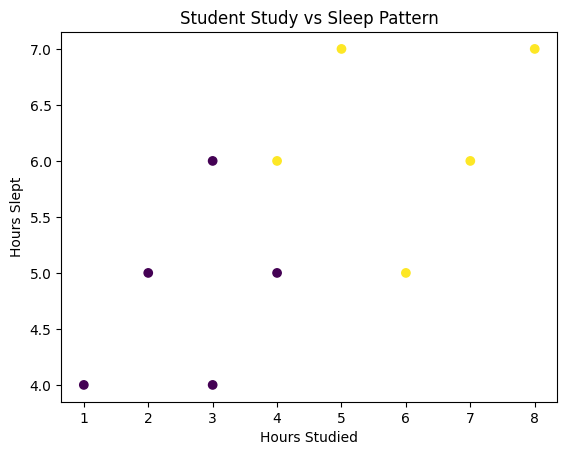

In [6]:
import matplotlib.pyplot as plt

plt.scatter(
    df["Hours_Studied"],
    df["Hours_Slept"],
    c=df["Label"]
)

plt.xlabel("Hours Studied")
plt.ylabel("Hours Slept")
plt.title("Student Study vs Sleep Pattern")

plt.show()

# ============================================================
# STEP 4: DATA MODELING
# ============================================================
#
# Machine Learning allows computers to learn patterns
# from historical data.
#
# Features
# --------
# Information used to make predictions.
#
# In this example:
# - Hours Studied
# - Hours Slept
#
# Target
# ------
# The outcome we want to predict.
#
# In this example:
# Pass or Fail
#
# ============================================================

In [7]:
X = df[["Hours_Studied", "Hours_Slept"]]

y = df["Label"]

# ============================================================
# SPLIT DATA
# ============================================================
#
# Why split data?
#
# Training Set:
# Used for learning.
#
# Testing Set:
# Used for checking performance.
#
# Typical split:
# 70% Training
# 30% Testing
#
# ============================================================

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42
)

# ============================================================
# BUILD MODEL
# ============================================================
#
# Decision Tree:
#
# One of the simplest machine learning algorithms.
#
# It learns patterns using a series of decisions.
#
# Example:
#
# IF Hours Studied > 4
# THEN Pass
#
# IF Hours Studied <= 4
# THEN Fail
#
# The computer automatically discovers these rules.
#
# ============================================================

In [9]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier()

model.fit(X_train, y_train)

print("\n========== MODEL TRAINED ==========")



========== MODEL TRAINED ==========


# ============================================================
# MAKE A PREDICTION
# ============================================================
#
# New Student:
# - Hours Studied = 5
# - Hours Slept = 6
#
# Can our AI predict the result?
#
# ============================================================


In [10]:
new_student = [[5, 6]]

prediction = model.predict(new_student)

print("\n========== NEW STUDENT PREDICTION ==========")

if prediction[0] == 1:
    print("PASS")
else:
    print("FAIL")


========== NEW STUDENT PREDICTION ==========
PASS


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


# ============================================================
# STEP 5: EVALUATION
# ============================================================
#
# Evaluation tells us how good the model is.
#
# Accuracy:
#
# Percentage of correct predictions.
#
# Example:
#
# Accuracy = 0.90
#
# Meaning:
# 90% of predictions are correct.
#
# ============================================================

In [11]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

y_pred = model.predict(X_test)

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("\n========== MODEL ACCURACY ==========")
print(accuracy)


========== MODEL ACCURACY ==========
0.6666666666666666


# ============================================================
# CONFUSION MATRIX
# ============================================================
#
# It shows:
#
# Correct Pass Predictions
# Incorrect Pass Predictions
# Correct Fail Predictions
# Incorrect Fail Predictions
#
# ============================================================


In [12]:
print("\n========== CONFUSION MATRIX ==========")
print(confusion_matrix(y_test, y_pred))


========== CONFUSION MATRIX ==========
[[1 1]
 [0 1]]


# ============================================================
# CLASSIFICATION REPORT
# ============================================================
#
# Precision:
# How many predicted positives were correct?
#
# Recall:
# How many actual positives were detected?
#
# F1 Score:
# Balance between Precision and Recall.
#
# ============================================================

In [ ]:
print("\n========== CLASSIFICATION REPORT ==========")
print(classification_report(y_test, y_pred))

# ============================================================
# BONUS: RULE-BASED AI
# ============================================================
#
# Before Machine Learning became popular,
# many systems used manually created rules.
#
# Example:
#
# IF Study + Sleep >= 10
# THEN PASS
#
# ELSE FAIL
#
# This is Rule-Based AI.
#
# ============================================================

In [13]:
def predict_result(hours_studied, hours_slept):

    if hours_studied + hours_slept >= 10:
        return "Pass"
    else:
        return "Fail"

print("\n========== RULE-BASED PREDICTIONS ==========")

student_A = predict_result(8, 7)
student_B = predict_result(2, 4)
student_C = predict_result(5, 5)

print("Student A:", student_A)
print("Student B:", student_B)
print("Student C:", student_C)


========== RULE-BASED PREDICTIONS ==========
Student A: Pass
Student B: Fail
Student C: Pass


# ============================================================
# REFLECTION QUESTIONS
# ============================================================
#
# 1. Why do we preprocess data?
#
# 2. What is the difference between
#    Rule-Based AI and Machine Learning?
#
# 3. Which step comes before Data Modeling?
#
# 4. What does Accuracy mean?
#
# 5. Can you think of a Cybersecurity problem
#    that can use Classification?
#
# Examples:
# - Spam Detection
# - Malware Detection
# - Phishing Detection
# - Intrusion Detection
#
# ============================================================

In [14]:
print("\nWorkshop Completed Successfully!")


Workshop Completed Successfully!
